# Synthetic noise study

Compare the methods at noise parameters **$\eta=0.1,0.2,0.4$** for all three overlaps. Measurements follow $d=\eta\,\operatorname{Poisson}(\widetilde d/\eta)$, so the noiseless mean is preserved and larger $\eta$ gives larger variance.

Each method retains its parameter pair selected at $\eta=0.1$. The budgets are 3,000, 800, and 200 epochs at 75%, 87.5%, and 93.75% overlap, with batch 27. The $\eta=0.1$ records are reused from the overlap study.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (path / "pyproject.toml").is_file()
            and (path / "results" / "endpoints.csv").is_file())
sys.path.insert(0, str(ROOT / "src"))
pd.options.display.float_format = lambda value: f"{value:.4g}"

from blind_magpie.results import selected_cases, plot_noise
STUDY = "noise"

## Recorded parameters and final errors

The curves report normalized squared complex errors,
$\mathrm{NMSE}_X=\|X_{\mathrm{al}}-X^\star\|_2^2/\|X^\star\|_2^2$.
The object is aligned by a complex scale and affine phase ramp on the common scanned region. The probe uses the corresponding ambiguity correction and its remaining global phase is removed.


In [2]:
selected = selected_cases(STUDY)
display(selected[["method", "overlap", "eta", "batch_size", "epochs", "parameters", "object_nmse", "probe_nmse"]])

,method,overlap,eta,batch_size,epochs,parameters,object_nmse,probe_nmse
0,rpie,0.75,0.1,27,3000,"αO=0.02, αP=0.1",0.007995,0.3978
1,lsqml,0.75,0.1,27,3000,"damping=0.04, σ=0.4",0.03178,0.9319
2,gm_rpie,0.75,0.1,27,3000,"αO=0.02, αP=0.1",0.002286,7.279e-05
3,gm_magpie,0.75,0.1,27,3000,"αO=0.1, αP=0.02",0.002079,0.0001374
4,rpie,0.75,0.2,27,3000,"αO=0.02, αP=0.1",0.03119,0.3763
5,lsqml,0.75,0.2,27,3000,"damping=0.04, σ=0.4",0.03213,0.9633
6,gm_rpie,0.75,0.2,27,3000,"αO=0.02, αP=0.1",0.007906,0.0002465
7,gm_magpie,0.75,0.2,27,3000,"αO=0.1, αP=0.02",0.005519,0.0002921
8,rpie,0.75,0.4,27,3000,"αO=0.02, αP=0.1",0.01055,0.2639
9,lsqml,0.75,0.4,27,3000,"damping=0.04, σ=0.4",0.03358,1.094


## Final object error

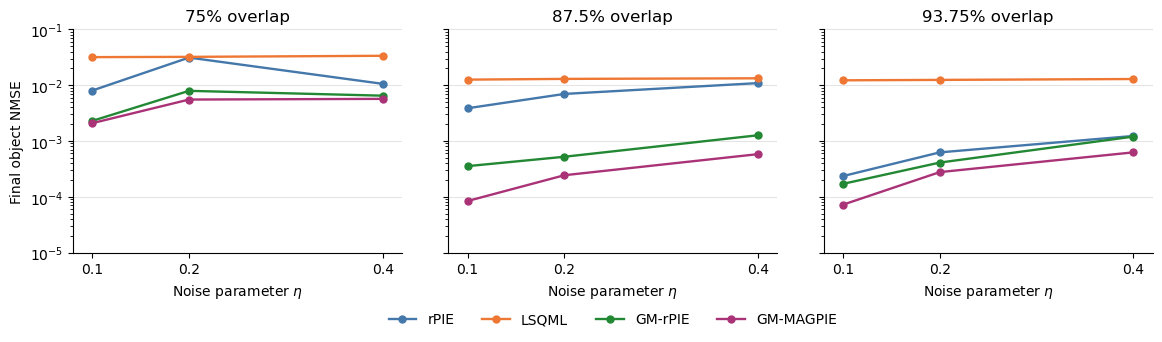

In [3]:
display(plot_noise(metric="object"))
plt.close("all")

## Final probe error

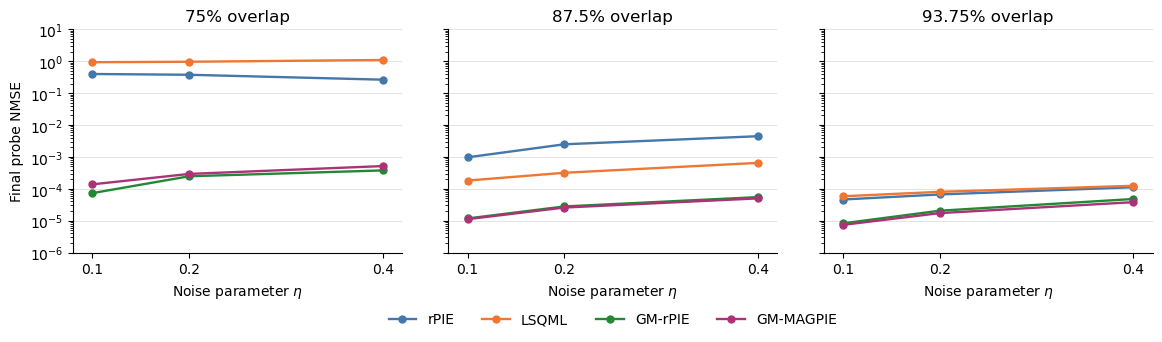

In [4]:
display(plot_noise(metric="probe"))
plt.close("all")

## Reproduce the synthetic reconstructions

The cells above use the recorded results and run on CPU. To compute new reconstructions, install the reconstruction dependencies and use a CUDA GPU. Set the flag below to `True` to rerun the selected parameter pairs; new outputs go into `runs/`.


In [5]:
RUN_RECONSTRUCTIONS = False
if RUN_RECONSTRUCTIONS:
    from blind_magpie import run_experiments
    display(run_experiments(STUDY, mode="selected", output=ROOT / "runs"))
